# # TACO Dataset — Validation & EDA
Object Detection component for Around You (Cleanliness Score)

In [1]:
import json
import pandas as pd
from pathlib import Path


TACO_DATA_DIR = Path(r"D:\Data Science - SP\Internships\Deep Learning-NLP-GenAI\AroundYou\TACO\data")
ANNOTATIONS_PATH = TACO_DATA_DIR / "annotations.json"

with open(ANNOTATIONS_PATH, "r") as f:
    coco_data = json.load(f)

print("Top-level keys:", coco_data.keys())
print("Number of images:", len(coco_data["images"]))
print("Number of annotations:", len(coco_data["annotations"]))
print("Number of categories:", len(coco_data["categories"]))

Top-level keys: dict_keys(['info', 'images', 'annotations', 'scene_annotations', 'licenses', 'categories', 'scene_categories'])
Number of images: 1500
Number of annotations: 4784
Number of categories: 60


## Data Validation — Class Distribution

In [2]:
# Building a lookup from category ID to category name
category_names = {cat["id"]: cat["name"] for cat in coco_data["categories"]}

# Counting how many annotations exist per category
category_counts = pd.Series(
    [category_names[ann["category_id"]] for ann in coco_data["annotations"]]
).value_counts()

print("Top 15 most common categories:")
print(category_counts.head(15))

print("\nBottom 15 least common categories:")
print(category_counts.tail(15))

print(f"\nTotal categories with at least 1 example: {len(category_counts)}")
print(f"Categories with fewer than 10 examples: {(category_counts < 10).sum()}")

Top 15 most common categories:
Cigarette                 667
Unlabeled litter          517
Plastic film              451
Clear plastic bottle      285
Other plastic             273
Other plastic wrapper     260
Drink can                 229
Plastic bottle cap        209
Plastic straw             157
Broken glass              138
Styrofoam piece           112
Glass bottle              104
Disposable plastic cup    104
Pop tab                    99
Other carton               93
Name: count, dtype: int64

Bottom 15 least common categories:
Shoe                       7
Glass cup                  6
Glass jar                  6
Aluminium blister pack     6
Other plastic container    6
Toilet tube                5
Six pack rings             5
Paper straw                4
Plastic glooves            4
Tupperware                 4
Polypropylene bag          3
Pizza box                  3
Battery                    2
Other plastic cup          2
Carded blister pack        1
Name: count, dtype: in

## Modeling Change — Category Collapsing

TACO's 59 real waste categories are severely imbalanced (18 have <10 examples). For our Cleanliness Score use case, the specific TYPE of litter is irrelevant — we only need to know whether litter is present. All categories are collapsed into a single "Litter" class.

In [3]:
# Collapse all categories into one binary class: litter present or not
for ann in coco_data["annotations"]:
    ann["category_id"] = 0  # single unified class

unified_categories = [{"id": 0, "name": "litter"}]

print(f"Total annotations, now all under one class: {len(coco_data['annotations'])}")
print("This resolves the class-imbalance problem entirely — every")
print("annotation now belongs to the same, well-populated class.")

Total annotations, now all under one class: 4784
This resolves the class-imbalance problem entirely — every
annotation now belongs to the same, well-populated class.


In [4]:
# Build a lookup: image_id -> list of its annotations
image_id_to_anns = {}
for ann in coco_data["annotations"]:
    image_id_to_anns.setdefault(ann["image_id"], []).append(ann)

# Build a lookup: image_id -> image metadata (filename, etc.)
image_id_to_info = {img["id"]: img for img in coco_data["images"]}

print(f"Images with annotations: {len(image_id_to_anns)}")
print(f"Total images in dataset: {len(image_id_to_info)}")

Images with annotations: 1500
Total images in dataset: 1500


## Data Validation — Visual Inspection of Annotations

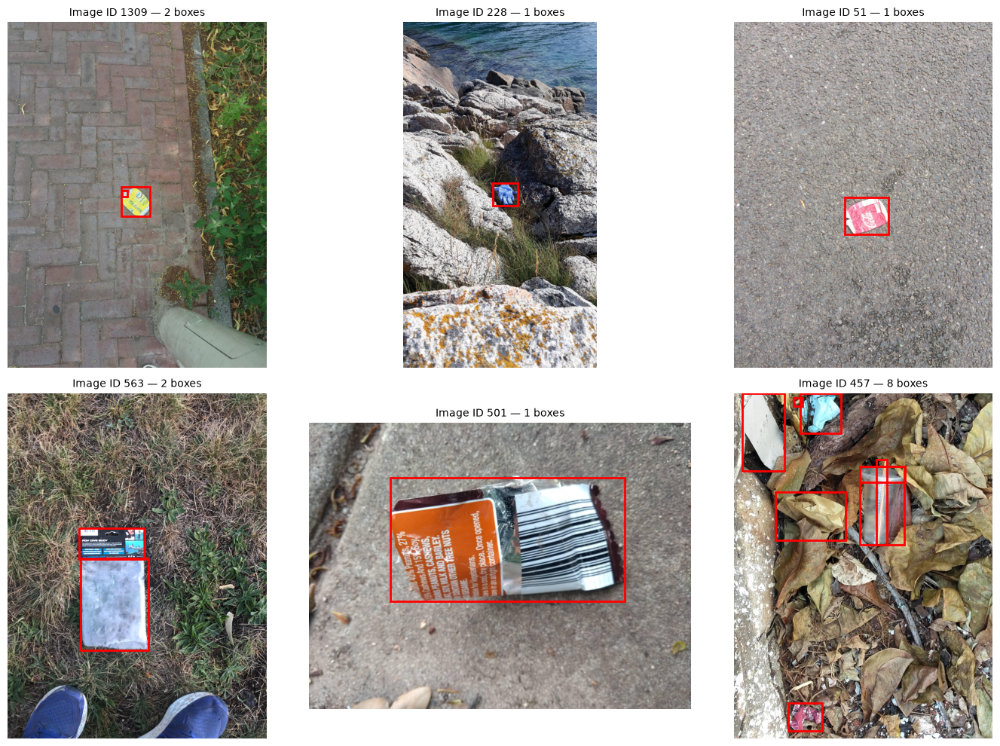

In [5]:
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import random

random.seed(42)
sample_image_ids = random.sample(list(image_id_to_anns.keys()), 6)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for idx, img_id in enumerate(sample_image_ids):
    img_info = image_id_to_info[img_id]
    img_path = TACO_DATA_DIR / img_info["file_name"]

    img = Image.open(img_path)
    img = ImageOps.exif_transpose(img)  # <-- the fix
    axes[idx].imshow(img)
    axes[idx].set_title(f"Image ID {img_id} — {len(image_id_to_anns[img_id])} boxes", fontsize=10)
    axes[idx].axis("off")

    for ann in image_id_to_anns[img_id]:
        x, y, w, h = ann["bbox"]
        rect = patches.Rectangle((x, y), w, h, linewidth=2, edgecolor="red", facecolor="none")
        axes[idx].add_patch(rect)

plt.tight_layout()
plt.show()

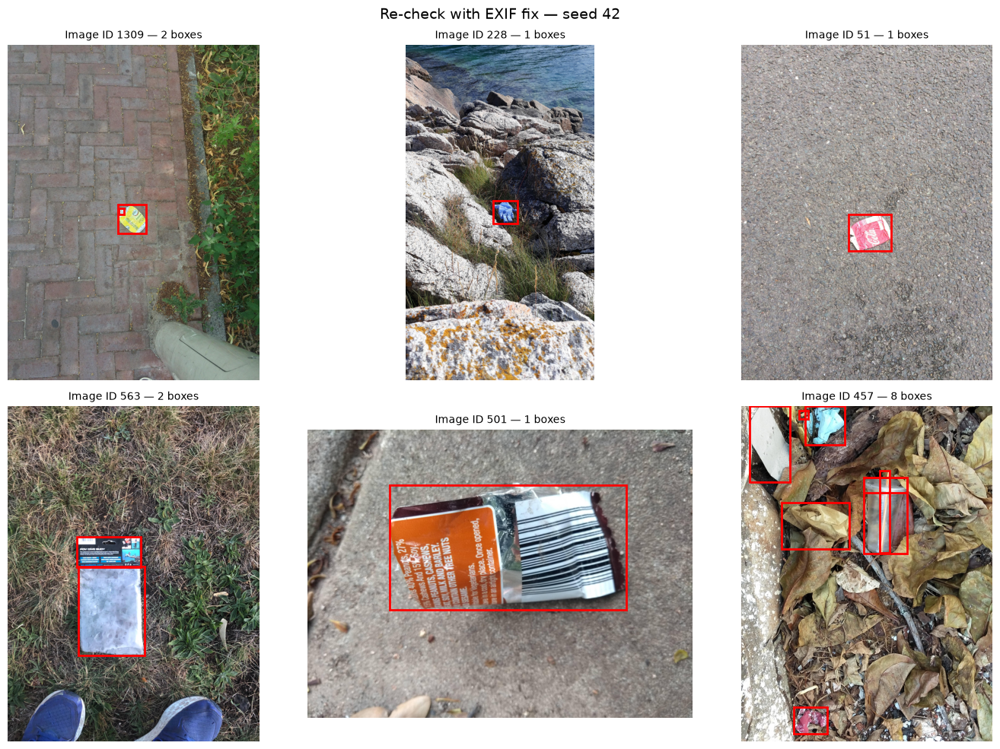

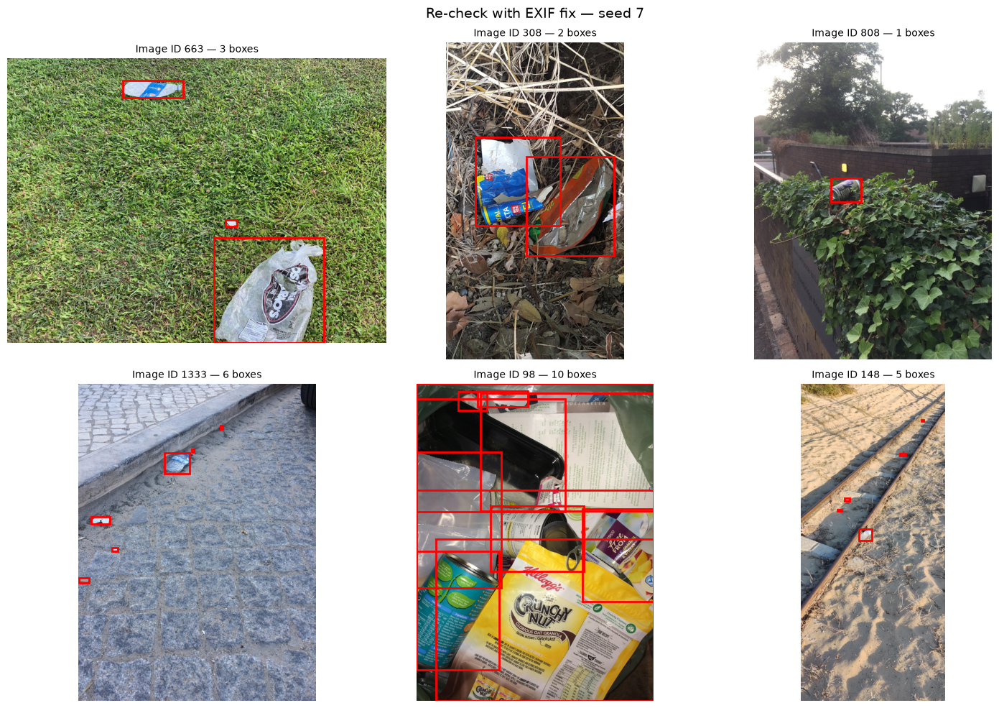

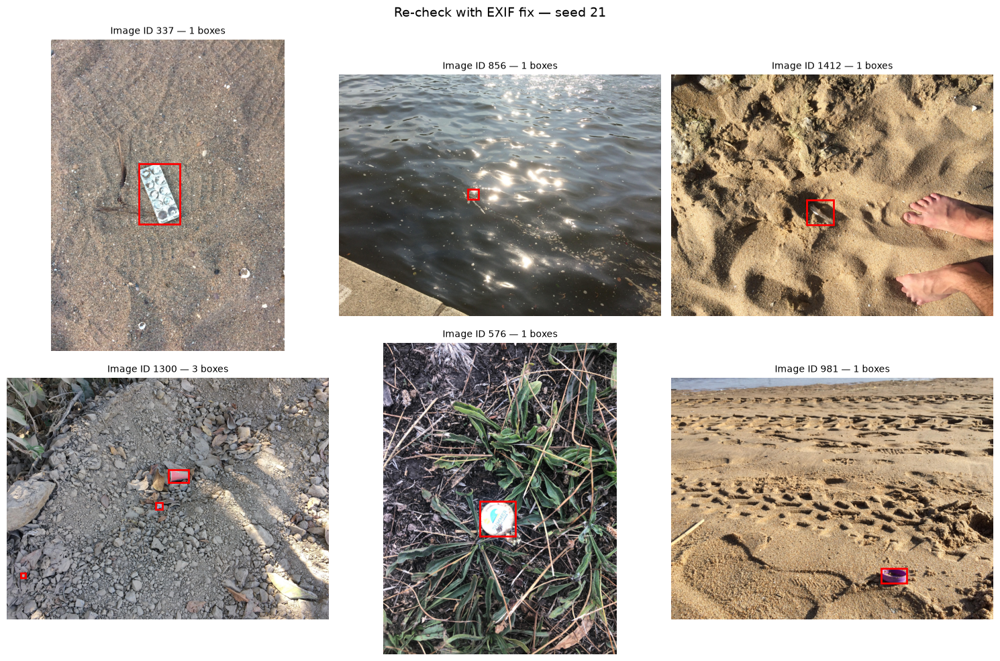

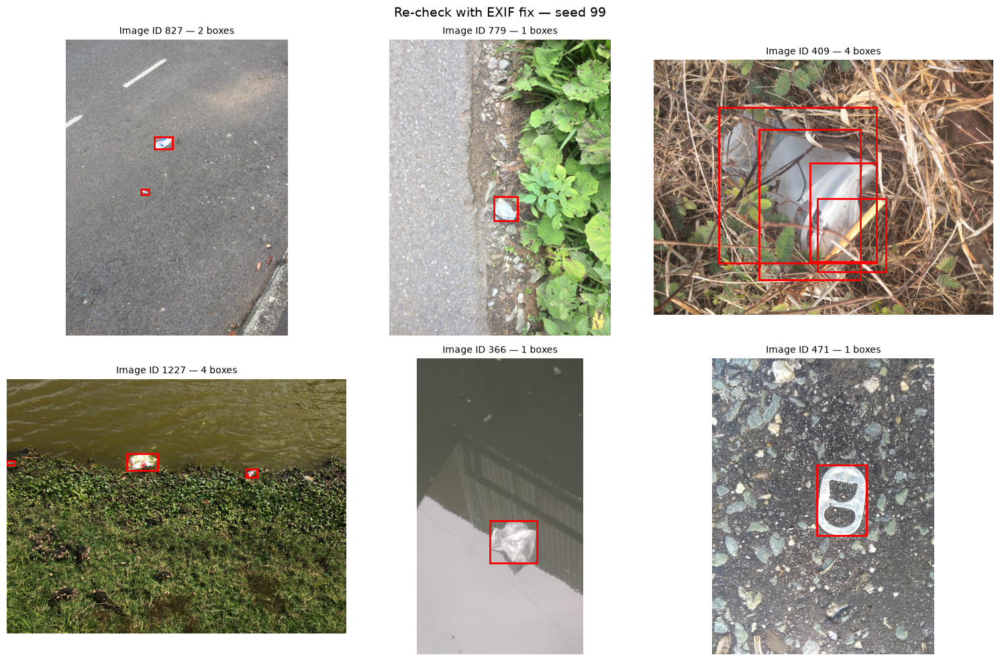

In [6]:
seeds_to_check = [42, 7, 21, 99]

for seed in seeds_to_check:
    random.seed(seed)
    sample_image_ids = random.sample(list(image_id_to_anns.keys()), 6)

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    axes = axes.flatten()

    for idx, img_id in enumerate(sample_image_ids):
        img_info = image_id_to_info[img_id]
        img_path = TACO_DATA_DIR / img_info["file_name"]

        img = Image.open(img_path)
        img = ImageOps.exif_transpose(img)  # fix applied everywhere now
        axes[idx].imshow(img)
        axes[idx].set_title(f"Image ID {img_id} — {len(image_id_to_anns[img_id])} boxes", fontsize=10)
        axes[idx].axis("off")

        for ann in image_id_to_anns[img_id]:
            x, y, w, h = ann["bbox"]
            rect = patches.Rectangle((x, y), w, h, linewidth=2, edgecolor="red", facecolor="none")
            axes[idx].add_patch(rect)

    plt.suptitle(f"Re-check with EXIF fix — seed {seed}", fontsize=14)
    plt.tight_layout()
    plt.show()

## Train / Validation / Test Split

In [7]:
from sklearn.model_selection import train_test_split

# Split at the IMAGE level, not annotation level — every box from the
# same image must stay together in the same split, otherwise the model
# could "cheat" by seeing near-duplicate crops of the same scene in
# both training and test data
all_image_ids = list(image_id_to_anns.keys())

train_ids, temp_ids = train_test_split(
    all_image_ids, test_size=0.30, random_state=42
)
val_ids, test_ids = train_test_split(
    temp_ids, test_size=0.50, random_state=42
)

print(f"Train images: {len(train_ids)}")
print(f"Validation images: {len(val_ids)}")
print(f"Test images: {len(test_ids)}")

print(f"\nTrain annotations: {sum(len(image_id_to_anns[i]) for i in train_ids)}")
print(f"Validation annotations: {sum(len(image_id_to_anns[i]) for i in val_ids)}")
print(f"Test annotations: {sum(len(image_id_to_anns[i]) for i in test_ids)}")

Train images: 1050
Validation images: 225
Test images: 225

Train annotations: 3409
Validation annotations: 695
Test annotations: 680


In [8]:
total_images_in_dataset = len(coco_data["images"])
images_with_annotations = len(image_id_to_anns)
images_with_zero_annotations = total_images_in_dataset - images_with_annotations

print(f"Total images in TACO: {total_images_in_dataset}")
print(f"Images with at least 1 annotation: {images_with_annotations}")
print(f"Images with ZERO annotations: {images_with_zero_annotations}")

Total images in TACO: 1500
Images with at least 1 annotation: 1500
Images with ZERO annotations: 0


## Image Preparation

In [9]:
from PIL import Image, ImageOps

sample_check_ids = random.sample(all_image_ids, 20)
sizes = []

for img_id in sample_check_ids:
    img_info = image_id_to_info[img_id]
    img_path = TACO_DATA_DIR / img_info["file_name"]
    img = Image.open(img_path)
    img = ImageOps.exif_transpose(img)
    sizes.append(img.size)

widths = [s[0] for s in sizes]
heights = [s[1] for s in sizes]

print("Sample of 20 real image dimensions (width x height):")
for s in sizes:
    print(s)

print(f"\nWidth range: {min(widths)} to {max(widths)}")
print(f"Height range: {min(heights)} to {max(heights)}")

Sample of 20 real image dimensions (width x height):
(4160, 3120)
(3024, 4032)
(1824, 4000)
(4160, 3120)
(1824, 4000)
(2448, 3264)
(2448, 3264)
(3264, 2448)
(2448, 3264)
(2275, 3235)
(4000, 1824)
(3264, 2448)
(3264, 2448)
(4160, 3120)
(2448, 3011)
(1824, 4000)
(2448, 3264)
(2448, 3264)
(3120, 4160)
(2448, 3264)

Width range: 1824 to 4160
Height range: 1824 to 4160


## Letterbox Resize (preserves aspect ratio, pads to square)
Target size: 640x640, standard for modern object detectors.

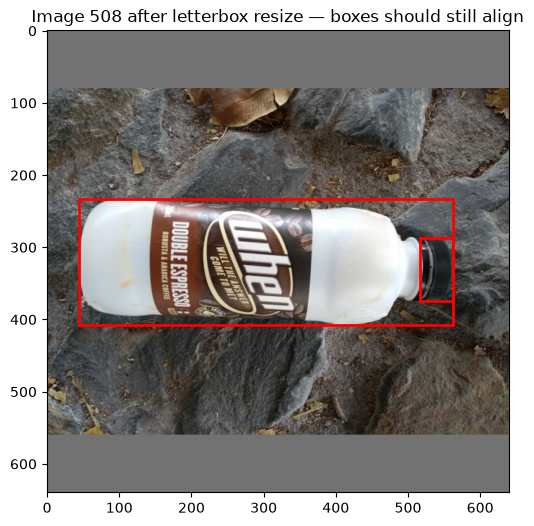

In [10]:
import numpy as np

TARGET_SIZE = 640

def letterbox_resize(img, bboxes, target_size=TARGET_SIZE):
    """Resizes an image to target_size x target_size, preserving aspect
    ratio via padding, and transforms bounding boxes to match."""
    orig_w, orig_h = img.size
    scale = target_size / max(orig_w, orig_h)
    new_w, new_h = int(orig_w * scale), int(orig_h * scale)

    img_resized = img.resize((new_w, new_h))

    # Center the resized image on a gray square canvas
    canvas = Image.new("RGB", (target_size, target_size), (114, 114, 114))
    pad_x = (target_size - new_w) // 2
    pad_y = (target_size - new_h) // 2
    canvas.paste(img_resized, (pad_x, pad_y))

    # Apply the SAME scale + pad transform to every bounding box
    new_bboxes = []
    for (x, y, w, h) in bboxes:
        new_bboxes.append([
            x * scale + pad_x,
            y * scale + pad_y,
            w * scale,
            h * scale,
        ])

    return canvas, new_bboxes

# Test it on one real image + visually confirm boxes still align
test_id = sample_check_ids[0]
img_info = image_id_to_info[test_id]
img = ImageOps.exif_transpose(Image.open(TACO_DATA_DIR / img_info["file_name"]))
bboxes = [ann["bbox"] for ann in image_id_to_anns[test_id]]

resized_img, resized_bboxes = letterbox_resize(img, bboxes)

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(resized_img)
for (x, y, w, h) in resized_bboxes:
    rect = patches.Rectangle((x, y), w, h, linewidth=2, edgecolor="red", facecolor="none")
    ax.add_patch(rect)
ax.set_title(f"Image {test_id} after letterbox resize — boxes should still align")
plt.show()

## Applying Preprocessing Across the Full Dataset

In [11]:
import os

# Saving the processed, resized images + their transformed labels
PROCESSED_DIR = Path("processed_data")
for split_name in ["train", "val", "test"]:
    (PROCESSED_DIR / split_name / "images").mkdir(parents=True, exist_ok=True)
    (PROCESSED_DIR / split_name / "labels").mkdir(parents=True, exist_ok=True)

def process_split(image_ids, split_name):
    """Applies EXIF fix + letterbox resize to every image in a split,
    saves the resized image and its transformed bounding boxes."""
    skipped = []

    for img_id in image_ids:
        img_info = image_id_to_info[img_id]
        img_path = TACO_DATA_DIR / img_info["file_name"]

        try:
            img = Image.open(img_path)
            img = ImageOps.exif_transpose(img)
        except (FileNotFoundError, OSError) as e:
            skipped.append((img_id, str(e)))
            continue

        bboxes = [ann["bbox"] for ann in image_id_to_anns[img_id]]
        resized_img, resized_bboxes = letterbox_resize(img, bboxes)

        # Save the processed image
        out_name = f"{img_id}.jpg"
        resized_img.save(PROCESSED_DIR / split_name / "images" / out_name)

        # Save labels in a simple format: class_id x y w h (one line per box)
        label_path = PROCESSED_DIR / split_name / "labels" / f"{img_id}.txt"
        with open(label_path, "w") as f:
            for (x, y, w, h) in resized_bboxes:
                f.write(f"0 {x:.2f} {y:.2f} {w:.2f} {h:.2f}\n")

    return skipped

train_skipped = process_split(train_ids, "train")
val_skipped = process_split(val_ids, "val")
test_skipped = process_split(test_ids, "test")

print(f"Train: {len(train_ids) - len(train_skipped)} processed, {len(train_skipped)} skipped")
print(f"Val:   {len(val_ids) - len(val_skipped)} processed, {len(val_skipped)} skipped")
print(f"Test:  {len(test_ids) - len(test_skipped)} processed, {len(test_skipped)} skipped")

if train_skipped or val_skipped or test_skipped:
    print("\nSkipped images (likely missing/corrupted files):")
    for img_id, err in (train_skipped + val_skipped + test_skipped):
        print(f"  {img_id}: {err}")

Train: 1050 processed, 0 skipped
Val:   225 processed, 0 skipped
Test:  225 processed, 0 skipped


## GPU / CUDA Verification

In [12]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("GPU name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

CUDA available: True
GPU name: NVIDIA GeForce GTX 1650


## Converting Labels to YOLO Format

In [13]:
import os

# YOLO needs: one .txt file per image, each line = "class_id x_center y_center width height"
# ALL VALUES NORMALIZED to 0-1 (relative to image width/height), NOT absolute pixels

def convert_to_yolo_format(bbox, img_width, img_height):
    """Converts a COCO-style box [x_min, y_min, w, h] in absolute pixels
    into YOLO's normalized [x_center, y_center, w, h] format."""
    x_min, y_min, w, h = bbox

    x_center = (x_min + w / 2) / img_width
    y_center = (y_min + h / 2) / img_height
    w_norm = w / img_width
    h_norm = h / img_height

    return x_center, y_center, w_norm, h_norm

test_id = train_ids[0]
img_info = image_id_to_info[test_id]
test_bbox = image_id_to_anns[test_id][0]["bbox"]

yolo_box = convert_to_yolo_format(test_bbox, img_info["width"], img_info["height"])
print(f"Original COCO bbox (pixels): {test_bbox}")
print(f"Converted YOLO bbox (normalized): {yolo_box}")
print(f"All 4 values should be between 0 and 1: {all(0 <= v <= 1 for v in yolo_box)}")

Original COCO bbox (pixels): [412.0, 2266.0, 414.0, 410.0]
Converted YOLO bbox (normalized): (0.14879807692307692, 0.7919871794871794, 0.09951923076923076, 0.13141025641025642)
All 4 values should be between 0 and 1: True


## Applying YOLO Conversion + Writing Final Dataset Structure

In [14]:
# Ultralytics/YOLO expects a specific folder structure:
#   dataset/
#     train/images/*.jpg   train/labels/*.txt
#     val/images/*.jpg     val/labels/*.txt
#     test/images/*.jpg    test/labels/*.txt
# We already have the resized IMAGES from before (in processed_data/).
# Now we write the matching LABEL files in proper YOLO format.

YOLO_DIR = Path("yolo_dataset")
for split_name in ["train", "val", "test"]:
    (YOLO_DIR / split_name / "images").mkdir(parents=True, exist_ok=True)
    (YOLO_DIR / split_name / "labels").mkdir(parents=True, exist_ok=True)

def write_yolo_labels(image_ids, split_name):
    """For each image, copies its already-resized 640x640 image into the
    YOLO folder structure, and writes a matching YOLO-format label file
    using the LETTERBOXED bbox coordinates (not the original ones) —
    since the images being used are the resized versions."""
    import shutil

    written = 0
    for img_id in image_ids:
        # Source: our already-processed, letterboxed 640x640 image
        src_img_path = PROCESSED_DIR / split_name / "images" / f"{img_id}.jpg"
        if not src_img_path.exists():
            continue

        # Copy the image into the new YOLO folder structure
        dst_img_path = YOLO_DIR / split_name / "images" / f"{img_id}.jpg"
        shutil.copy(src_img_path, dst_img_path)

        # Read the letterboxed labels we already saved earlier
        # (these are in absolute pixel coords, on the 640x640 image)
        src_label_path = PROCESSED_DIR / split_name / "labels" / f"{img_id}.txt"
        yolo_lines = []
        with open(src_label_path, "r") as f:
            for line in f:
                class_id, x, y, w, h = map(float, line.strip().split())
                # Image is now exactly 640x640 (letterboxed), so normalize by that
                x_center, y_center, w_norm, h_norm = convert_to_yolo_format(
                    (x, y, w, h), 640, 640
                )
                yolo_lines.append(f"{int(class_id)} {x_center:.6f} {y_center:.6f} {w_norm:.6f} {h_norm:.6f}")

        dst_label_path = YOLO_DIR / split_name / "labels" / f"{img_id}.txt"
        with open(dst_label_path, "w") as f:
            f.write("\n".join(yolo_lines))

        written += 1

    return written

train_written = write_yolo_labels(train_ids, "train")
val_written = write_yolo_labels(val_ids, "val")
test_written = write_yolo_labels(test_ids, "test")

print(f"Train: {train_written} images written")
print(f"Val: {val_written} images written")
print(f"Test: {test_written} images written")

Train: 1050 images written
Val: 225 images written
Test: 225 images written


## YOLO Dataset Configuration

In [15]:
yaml_content = f"""
path: {YOLO_DIR.resolve()}
train: train/images
val: val/images
test: test/images

names:
  0: litter
"""

yaml_path = YOLO_DIR / "data.yaml"
with open(yaml_path, "w") as f:
    f.write(yaml_content)

print("data.yaml written to:", yaml_path.resolve())
print("\nContents:")
print(yaml_content)

data.yaml written to: D:\Data Science - SP\Internships\Deep Learning-NLP-GenAI\AroundYou\cv_object_detection\yolo_dataset\data.yaml

Contents:

path: D:\Data Science - SP\Internships\Deep Learning-NLP-GenAI\AroundYou\cv_object_detection\yolo_dataset
train: train/images
val: val/images
test: test/images

names:
  0: litter



## Training — YOLOv8 Transfer Learning

In [16]:
from ultralytics import YOLO

# Load a PRETRAINED YOLOv8 nano model (trained on COCO)
model = YOLO("yolov8n.pt")

# Fine-tune it on our litter dataset
results = model.train(
    data=str(yaml_path),
    epochs=50,
    imgsz=640,
    batch=8,          # kept modest for a 4GB GPU (GTX 1650)
    device=0,          # use the GPU (device 0 = your GTX 1650)
    project="litter_detection",
    name="run1",
)

New https://pypi.org/project/ultralytics/8.4.144 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.142  Python-3.12.10 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=yolo_dataset\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yol

KeyboardInterrupt: 

## Evaluation — Visual Inspection of Predictions on Test Set

In [ ]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
from PIL import Image
import random

# Load the best-performing checkpoint from training
best_model = YOLO("runs/detect/litter_detection/run1/weights/best.pt")

# Pick a random sample of real TEST images (never seen during training)
random.seed(42)
test_image_files = list((YOLO_DIR / "test" / "images").glob("*.jpg"))
sample_test_images = random.sample(test_image_files, 6)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for idx, img_path in enumerate(sample_test_images):
    # Run the actual model on this real image
    results = best_model(str(img_path), verbose=False)
    result = results[0]

    # result.plot() draws the model's PREDICTED boxes directly on the image
    annotated_img = result.plot()

    axes[idx].imshow(annotated_img[..., ::-1])  # BGR to RGB for matplotlib
    num_detections = len(result.boxes)
    axes[idx].set_title(f"{img_path.name} — {num_detections} detected", fontsize=10)
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

## Second Training Run — Larger Image Size to Address Small-Object Recall

In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")  # fresh pretrained start, same as before

results = model.train(
    data=str(yaml_path),
    epochs=75,
    imgsz=960,         # up from 640 — preserves more detail for small litter
    batch=4,            # reduced from 8, since imgsz=960 uses much more GPU memory
    device=0,
    project="litter_detection",
    name="run2",         # separate folder — run1 stays intact for comparison
)

In [17]:
from ultralytics import YOLO

model = YOLO("runs/detect/litter_detection/run2/weights/last.pt")

results = model.train(resume=True)

New https://pypi.org/project/ultralytics/8.4.144 available  Update with 'pip install -U ultralytics'
WARNING model 'runs\detect\litter_detection\run2\weights\last.pt' is not a resumable training checkpoint (missing epoch/optimizer state). Use 'resume' only to continue incomplete training. Starting new training instead.
Ultralytics 8.4.142  Python-3.12.10 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torch

KeyboardInterrupt: 

In [ ]:
import yaml

with open("runs/detect/litter_detection/run1/args.yaml", "r") as f:
    run1_args = yaml.safe_load(f)

augmentation_keys = ["hsv_h", "hsv_s", "hsv_v", "degrees", "translate",
                      "scale", "shear", "flipud", "fliplr", "mosaic",
                      "mixup", "copy_paste"]

print("Augmentation settings actually used in Run 1:")
for key in augmentation_keys:
    print(f"  {key}: {run1_args.get(key)}")

In [18]:
model = YOLO("yolov8n.pt")

results = model.train(
    data=str(yaml_path),
    epochs=50,
    imgsz=640,           # back to 640 — Run 2 showed resolution is not the bottleneck
    batch=8,
    device=0,
    copy_paste=0.3,        # was 0.0 — directly targets visual diversity within
                            # the single "Litter" class
    mixup=0.15,            # was 0.0 — helps generalization given our modest
                            # dataset size (~1,050 images)
    scale=0.9,             # increased from 0.5 — more size variation exposure
    project="litter_detection",
    name="run3",
)

New https://pypi.org/project/ultralytics/8.4.144 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.142  Python-3.12.10 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.3, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=yolo_dataset\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model=yo

## Insights

### Full Comparison

| Metric | Run 1 (baseline, 640px) | Run 2 (960px) | Run 3 (copy_paste + mixup) |
|---|---|---|---|
| Precision | **0.755** | 0.715 | 0.687 |
| Recall | 0.416 | 0.423 | 0.427 |
| mAP50 | **0.492** | 0.487 | 0.487 |
| mAP50-95 | **0.346** | 0.344 | 0.340 |

### Second Hypothesis Tested
we tested whether increased data augmentation — specifically `copy_paste` (0.0 → 0.3) and `mixup`
(0.0 → 0.15), both confirmed inactive in Run 1's actual training
settings — would improve recall by exposing the model to more visual
diversity within the single "Litter" class.

### Result: Consistent with Run 2 — Hypothesis Not Confirmed

Recall improved only marginally (0.416 → 0.427, a 0.011 change), while
precision declined further (0.755 → 0.687). This is the **second
independent, well-reasoned intervention** — targeting a genuinely
different mechanism than Run 2's resolution change — to produce
essentially the same flat/declining pattern.

### Strengthened Conclusion

A pattern observed across two different, independently-motivated
experiments is a more reliable signal than either result alone. Neither
increased resolution (Run 2) nor increased augmentation diversity
(Run 3) meaningfully improved recall. This points toward a genuine
**dataset-volume ceiling** — approximately 1,050 training images
covering an inherently high-diversity single class ("Litter" spans
cigarette butts, bottles, wrappers, glass, etc.) — as the more likely
fundamental limitation, rather than a fixable training configuration
issue.

### Final Model Selection: Run 1

Run 1 is retained as the final model:
- Highest precision (0.755) of all three runs
- Highest mAP50 (0.492) and mAP50-95 (0.346) of all three runs
- Comparable recall to Runs 2 and 3 (differences of ~0.01, within
  normal run-to-run variation)
- Achieved in the least training time (~1.87 hours vs. longer runs)